# 1.3. Метод простых итераций и метод Зейделя

Реализация: `lab1/iterative.py`. Матрица, вектор и ε читаются из файлов.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"

from lab1.dataio import read_matrix, read_vector, read_scalar, read_tridiag
from lab1.matops import (
    mat_mul, mat_vec, identity, fmt_mat, fmt_vec, mat_sub, max_abs_mat, diag_from, transpose,
)

from lab1.iterative import simple_iteration, seidel
from lab1.lu import lu_decompose, lu_solve
import matplotlib.pyplot as plt
%matplotlib inline

A = read_matrix(DATA / "1_3" / "A.txt")
b = read_vector(DATA / "1_3" / "b.txt")
eps = read_scalar(DATA / "1_3" / "eps.txt")
print("A")
print(fmt_mat(A))
print("b =", fmt_vec(b))
print("n =", len(A))

A
            21              1             -8              4
            -9            -23             -2              4
             7             -1            -17              6
             8              8             -4            -26
b = [-119, 79, -24, -52]
n = 4


## Заданная точность

In [2]:
print("ε =", eps)

ε = 0.01


## Эталонное решение (через собственное LU)

In [3]:
L, U, P, swaps = lu_decompose(A)
x_exact = lu_solve(L, U, P, b)
print("эталон x =", fmt_vec(x_exact))

эталон x = [-6, -1, -1, 1.6786408e-16]


## Метод простых итераций

In [4]:
x_j, k_j, hist_j = simple_iteration(A, b, eps)
print("итераций:", k_j)
print("x =", fmt_vec(x_j))
print("||x - эталон||_inf =", max(abs(x_j[i] - x_exact[i]) for i in range(len(A))))

итераций: 10
x = [-5.9990569, -0.99969267, -0.99868852, -0.0022490231]
||x - эталон||_inf = 0.0022490231146344054


## Метод Зейделя

In [5]:
x_s, k_s, hist_s = seidel(A, b, eps)
print("итераций:", k_s)
print("x =", fmt_vec(x_s))
print("||x - эталон||_inf =", max(abs(x_s[i] - x_exact[i]) for i in range(len(A))))

итераций: 5
x = [-5.9993338, -1.0003729, -0.99964606, 3.5813408e-05]
||x - эталон||_inf = 0.000666236264342146


## Сравнение скорости сходимости

простые итерации: 10 итераций
Зейдель:          5 итераций
Зейдель сошёлся быстрее в 2.00 раза


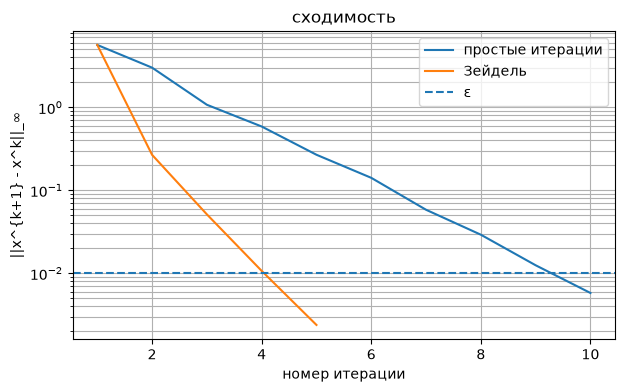

In [6]:
print("простые итерации: %d итераций" % k_j)
print("Зейдель:          %d итераций" % k_s)
if k_s < k_j:
    print("Зейдель сошёлся быстрее в %.2f раза" % (k_j / k_s))
elif k_j < k_s:
    print("простые итерации сошлись быстрее")
else:
    print("одинаковое число итераций")

plt.figure(figsize=(7, 4))
plt.semilogy(range(1, len(hist_j) + 1), hist_j, label="простые итерации")
plt.semilogy(range(1, len(hist_s) + 1), hist_s, label="Зейдель")
plt.axhline(eps, linestyle="--", label="ε")
plt.xlabel("номер итерации")
plt.ylabel("||x^{k+1} - x^k||_∞")
plt.title("сходимость")
plt.grid(True, which="both")
plt.legend()
plt.show()